# Five strongest input–flux associations

This notebook makes five figures and written explanations for the group
presentation. It runs independently with the course `.venv`, using
`sat3_loader.py` and `nonlinear_tools.py` in this folder. All 43 supplied
TGLF/SAT2 cases are included, including those flagged for review in Step 4.

## 1. Selection rule and scope

**“Strongest” means largest absolute Spearman correlation among 30 pairs:**
10 distinct physical input coordinates × the three primary flux outputs
(`Q_i`, `Q_e`, `Gamma_e`). Spearman correlation measures a consistently
increasing or decreasing trend, including a curved one. It does not capture
every possible nonlinear relationship. Pearson correlation on the original
values is reported alongside it. Each case has equal weight in both metrics.

This selection focuses on plasma inputs versus heat/particle fluxes. The full
screen still includes momentum, input–input, and flux–flux pairs, but those are
outside this five-plot ranking. Duplicate columns are checked and counted once:
`RLTS_1 = RLTS_2`, `RLNS_1 = RLNS_2`, and `Gamma_i = Gamma_e` in these data.
Magnetic shear replaces its encoded `Q_PRIME_LOC` coordinate when choosing the
10 physical inputs.

**Correlation strength is not statistical significance.** These 43 simulations
were chosen as a parameter scan, not sampled independently from a population.
We do not assign significance stars or rank conventional p-values. We report
how each correlation changes after removing each of the 26 letter groups.
Those ranges are sensitivity checks, not confidence intervals. The ranking
and its explanations remain exploratory after searching many pairs.
[SciPy's Spearman documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)
also cautions against using its asymptotic p-values for small samples.

Each figure has two panels: all cases on the left and a matched scan on the
right. Gray points provide context; colored points identify the matched cases.
Lines connect observed cases only. **The panels have separately labeled
vertical scales** to make the controlled scan readable. No cases are moved or
jittered, and no fitted curve or uncertainty band is added.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Locate the same source files from analysis/, task1/, or the course folder.
# The course workspace and the task directory both contain the same SAT3 data tree.
data_locations = (
    "datasets/SAT3_dataset_v1/SAT3_dataset/data",
    "assignments/task1/datasets/SAT3_dataset_v1/SAT3_dataset/data",
    "assignments/*/datasets/SAT3_dataset_v1/SAT3_dataset/data",
)
DATA_DIR = next(
    (path for base in (Path.cwd(), *Path.cwd().parents)
     for pattern in data_locations for path in sorted(base.glob(pattern))
     if path.is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Open this notebook from inside the DSC180A folder.")

analysis_dir = DATA_DIR.parents[3] / "analysis"
if str(analysis_dir) not in sys.path:
    sys.path.insert(0, str(analysis_dir))
from sat3_loader import load_cases, SCALAR_PARAMETERS, SPECIES_PARAMETERS

records, errors = load_cases(DATA_DIR)
if errors:
    raise ValueError(f"Some cases failed to load: {errors}")
if len(records) != 43:
    raise ValueError(f"Expected 43 supplied cases, found {len(records)}")
df = pd.DataFrame(records).set_index("case")
if not df.index.is_unique:
    raise ValueError("Case names must be unique")
if not (
    df["NS"].eq(2).all()
    and df["species_type_1"].eq("electron").all()
    and df["species_type_2"].isin(["H", "D", "T"]).all()
):
    raise ValueError("Check species ordering before assigning electron/ion labels")

plot_df = df.copy()
plot_df["letter"] = df.index.to_series().str.rsplit("_", n=1).str[0]
plot_df["ion"] = df["species_type_2"]
flux_aliases = {
    "Gamma_e": "Gamma_1", "Gamma_i": "Gamma_2",
    "Q_e": "Q_1", "Q_i": "Q_2",
    "Pi_e": "Pi_1", "Pi_i": "Pi_2",
}
for alias, source in flux_aliases.items():
    plot_df[alias] = df[source]
if plot_df[["Q_i", "Q_e"]].le(0).any().any():
    raise ValueError("Inspect nonpositive heat fluxes before log/ratio plots")

import json
from zipfile import ZipFile, ZIP_DEFLATED
from nonlinear_tools import dependency_screen

plot_df["magnetic_shear"] = plot_df["Q_PRIME_LOC"] * plot_df["RMIN_LOC"] ** 2 / plot_df["Q_LOC"] ** 2
physical_inputs = [
    "XNUE", "RLTS_2", "RLNS_2", "MASS_2", "TAUS_2", "magnetic_shear",
    "Q_LOC", "RMIN_LOC", "KAPPA_LOC", "DRMAJDX_LOC",
]
primary_fluxes = ["Q_i", "Q_e", "Gamma_e"]
for duplicate, retained in {"RLTS_1": "RLTS_2", "RLNS_1": "RLNS_2", "Gamma_i": "Gamma_e"}.items():
    if not plot_df[duplicate].equals(plot_df[retained]):
        raise ValueError(f"Revisit the selection scope: {duplicate} differs from {retained}")
if not np.isfinite(plot_df[physical_inputs + primary_fluxes].to_numpy()).all():
    raise ValueError("Resolve non-finite values before ranking")

OUTPUT_DIR = analysis_dir / "figures" / "top_correlations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 115, "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 12, "axes.titlesize": 12, "svg.fonttype": "none",
})
print(f"Loaded {len(plot_df)} cases across {plot_df['letter'].nunique()} letters.")

Loaded 43 cases across 26 letters.


## 2. Recompute the ranking and deletion sensitivity

This cell recomputes all 120 nonduplicate pairs from the source data and then
selects the 30 input–primary-flux pairs. The fifth and sixth pairs are close:
their absolute Spearman correlations differ by only about 0.005. Their order
should not be treated as a meaningful separation in scientific importance.

In [2]:
screen_inputs = physical_inputs + ["Q_PRIME_LOC"]
screen_outputs = primary_fluxes + ["Pi_e", "Pi_i"]
all_pairs = dependency_screen(
    plot_df, screen_inputs + screen_outputs,
    plot_df["letter"].to_numpy(), screen_inputs,
)
ranking = all_pairs.loc[
    all_pairs["variable_1"].isin(physical_inputs)
    & all_pairs["variable_2"].isin(primary_fluxes)
].copy()
ranking["absolute_spearman"] = ranking["spearman"].abs()
ranking = ranking.sort_values(
    ["absolute_spearman", "variable_1", "variable_2"],
    ascending=[False, True, True], kind="stable",
).reset_index(drop=True)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
top_five = ranking.head(5).copy()
assert len(all_pairs) == 120 and len(ranking) == 30
assert set(top_five["valid_deletions"]) == {26}
expected_pairs = [
    ("RLNS_2", "Gamma_e"), ("RLNS_2", "Q_e"), ("XNUE", "Q_i"),
    ("RLTS_2", "Q_i"), ("RLTS_2", "Q_e"),
]
if list(top_five[["variable_1", "variable_2"]].itertuples(index=False, name=None)) != expected_pairs:
    raise ValueError("The ranking changed; update the five written interpretations before using them")

display(top_five[[
    "rank", "variable_1", "variable_2", "spearman", "pearson",
    "spearman_delete_min", "spearman_delete_max",
]].round(3).rename(columns={
    "variable_1": "input", "variable_2": "flux",
    "spearman_delete_min": "rho_min_after_letter_removal",
    "spearman_delete_max": "rho_max_after_letter_removal",
}))
print("Sixth place:", ranking.loc[5, ["variable_1", "variable_2", "spearman"]].to_dict())

,rank,input,flux,spearman,pearson,rho_min_after_letter_removal,rho_max_after_letter_removal
0,1,RLNS_2,Gamma_e,0.764,0.814,0.703,0.784
1,2,RLNS_2,Q_e,0.645,0.753,0.552,0.740
2,3,XNUE,Q_i,-0.591,-0.355,-0.625,-0.465
3,4,RLTS_2,Q_i,0.577,0.548,0.431,0.621
4,5,RLTS_2,Q_e,0.518,0.278,0.347,0.604


Sixth place: {'variable_1': 'XNUE', 'variable_2': 'Q_e', 'spearman': -0.5128485528329276}


## 3. Plot construction and variable definitions

`RLNS_s` is the normalized density gradient, $-a\,d\ln n_s/dr$;
`RLTS_s` is the normalized temperature gradient, $-a\,d\ln T_s/dr$.
Larger values here mean a steeper outward decrease. `XNUE` is the normalized
electron–ion collision frequency. `Q_i`, `Q_e`, and `Gamma_e` denote ion heat,
electron heat, and electron particle flux in gyro-Bohm units.
[GACODE input definitions](https://gafusion.github.io/doc/tglf/tglf_list.html#rlns-1).

Both species' gradients change together. A temperature-gradient plot cannot
separate an electron-gradient effect from an ion-gradient effect in this scan.
For the matching below, magnetic shear is recovered as
`Q_PRIME_LOC * RMIN_LOC**2 / Q_LOC**2`, following
[GACODE's definition](https://gafusion.github.io/doc/tglf/tglf_list.html#q-prime-loc).

In the density and temperature plots, each colored isotope line holds the
other retained physical inputs at `a_D`, except for ion mass. In the collision
plot, both lines use deuterium and hold the remaining retained physical inputs
at baseline; the two lines distinguish density-gradient settings 1 and 3.

In [3]:
ion_colors = {"H": "#0072B2", "D": "#D55E00", "T": "#009E73"}
ion_markers = {"H": "o", "D": "s", "T": "^"}
x_labels = {
    "RLNS_2": "Shared density gradient: RLNS_1 = RLNS_2 (a/L_n)",
    "RLTS_2": "Shared temperature gradient: RLTS_1 = RLTS_2 (a/L_T)",
    "XNUE": "Electron-ion collision frequency: XNUE (log scale)",
}
y_labels = {
    "Gamma_e": "Electron particle flux, Gamma_e (gyro-Bohm)",
    "Q_e": "Electron heat flux, Q_e (gyro-Bohm)",
    "Q_i": "Ion heat flux, Q_i (gyro-Bohm)",
}
plot_records = []


def matched_groups(feature):
    free = {feature, "RLNS_2"} if feature == "XNUE" else {feature, "MASS_2"}
    held = [name for name in physical_inputs if name not in free]
    keep = np.isclose(
        plot_df[held].to_numpy(), plot_df.loc["a_D", held].to_numpy(dtype=float),
        rtol=1e-10, atol=1e-12,
    ).all(axis=1)
    matched = plot_df.loc[keep].copy()
    groups = []
    if feature == "XNUE":
        matched = matched.loc[matched["RLNS_2"].isin([1.0, 3.0])]
        for density, color, marker in [(1.0, "#0072B2", "o"), (3.0, "#D55E00", "s")]:
            group = matched.loc[matched["RLNS_2"].eq(density)].sort_values(feature)
            assert len(group) == 3 and group["ion"].eq("D").all()
            groups.append((f"RLNS_1 = RLNS_2 = {density:g}", color, marker, group))
    else:
        for ion in ("H", "D", "T"):
            group = matched.loc[matched["ion"].eq(ion)].sort_values(feature)
            assert len(group) == (3 if feature == "RLNS_2" else 4)
            groups.append((ion, ion_colors[ion], ion_markers[ion], group))
    # Verify that every individual line changes only the displayed coordinate.
    for _, _, _, group in groups:
        fixed = [name for name in physical_inputs if name != feature]
        assert group[fixed].round(12).nunique().eq(1).all()
    return groups


def plot_correlation(rank, title, filename):
    row = top_five.loc[top_five["rank"].eq(rank)].iloc[0]
    feature, target = row["variable_1"], row["variable_2"]
    groups = matched_groups(feature)
    fig, axes = plt.subplots(1, 2, figsize=(13.6, 6.7))
    fig.subplots_adjust(left=0.085, right=0.985, top=0.76, bottom=0.20, wspace=0.30)
    fig.text(0.085, 0.95, f"{rank:02d}  {title}", fontsize=19, weight="bold", va="top")
    fig.text(0.085, 0.886,
             f"All-case Spearman rho = {row.spearman:+.3f}    |    Pearson r = {row.pearson:+.3f}    |    43 TGLF/SAT2 cases",
             fontsize=12, color="#3C4B5B")
    left, right = axes
    left.scatter(plot_df[feature], plot_df[target], s=48, color="#ADB8C3",
                 edgecolor="white", linewidth=0.55, alpha=0.85, zorder=2)
    for label, color, marker, group in groups:
        left.scatter(group[feature], group[target], s=66, color=color, marker=marker,
                     edgecolor="white", linewidth=0.6, zorder=3)
        right.plot(group[feature], group[target], color=color, marker=marker,
                   linewidth=2.0, markersize=7, markeredgecolor="white", markeredgewidth=0.6,
                   label=label, zorder=3)
    left.set_title("All cases; colored points belong to the matched scan", loc="left", pad=12, fontsize=11)
    right.set_title("Matched deuterium scans" if feature == "XNUE" else "Matched isotope scans at XNUE = 0.1", loc="left", pad=12, fontsize=11)
    for ax in axes:
        ax.set_xlabel(x_labels[feature], labelpad=11, fontsize=10.5)
        ax.set_ylabel(y_labels[target], labelpad=9, fontsize=11)
        ax.grid(axis="x", visible=False)
        ax.grid(axis="y", color="#E3E8ED", linewidth=0.8)
        if feature == "XNUE":
            ax.set_xscale("log")
            ticks = [0.01, 0.05, 0.1, 1] if ax is left else [0.01, 0.1, 1]
            ax.set_xticks(ticks, [f"{value:g}" for value in ticks])
            ax.set_xlim(0.0075, 1.4)
            from matplotlib.ticker import NullLocator
            ax.xaxis.set_minor_locator(NullLocator())
        else:
            ticks = [1, 2, 3] if feature == "RLNS_2" else [1.5, 2.25, 3, 3.5]
            ax.set_xticks(ticks, [f"{value:g}" for value in ticks])
            ax.set_xlim(min(ticks) - 0.16, max(ticks) + 0.16)
        bottom, top = ax.get_ylim()
        if target != "Gamma_e":
            ax.set_ylim(0, top * 1.08)
        else:
            ax.set_ylim(min(-1, bottom), top * 1.08)
            ax.axhline(0, color="#6B7785", linewidth=0.8, zorder=1)
    right.legend(title="Shared density gradient" if feature == "XNUE" else "Ion species",
                 loc="upper right" if feature == "XNUE" else "upper left",
                 frameon=True, facecolor="white", edgecolor="#D5DDE5",
                 fontsize=10, title_fontsize=10)
    # Identify contextual cases without labeling every overlapping point.
    for case, offset, horizontal in [("x_T", (-8, 8), "right"), ("z_D", (8, 9), "left")]:
        if feature != "XNUE" and target == "Q_i" and case == "z_D":
            continue
        x, y = plot_df.loc[case, [feature, target]]
        left.annotate(case, (x, y), xytext=offset, textcoords="offset points",
                      fontsize=9, color="#4A5563", ha=horizontal)
    fig.text(0.085, 0.087,
             f"Remove one letter at a time: rho ranges from {row.spearman_delete_min:+.3f} to {row.spearman_delete_max:+.3f}. This is a sensitivity range, not a confidence interval.",
             fontsize=10, color="#465466")
    fig.text(0.085, 0.047,
             "Lines connect observed cases. Other retained physical inputs are fixed within each line; vertical scales differ between panels.",
             fontsize=10, color="#465466")
    paths = []
    for suffix in ("png", "svg"):
        output = OUTPUT_DIR / f"{filename}.{suffix}"
        fig.savefig(output, dpi=240, facecolor="white", bbox_inches="tight")
        paths.append(output)
    plot_records.append({
        "rank": int(rank), "input": feature, "flux": target,
        "matched_cases": [str(case) for _, _, _, group in groups for case in group.index],
        "files": [str(p.relative_to(analysis_dir)) for p in paths],
    })
    plt.show()
    plt.close(fig)

## 4. Plot 1: Density gradient and electron particle flux

**Variables.** `RLNS_2` is the normalized ion density gradient and equals the
electron density gradient `RLNS_1` in every case. `Gamma_e` is electron
particle flux; `Gamma_i` has identical values here.

**What the plot shows.** Spearman rho is **+0.764** and Pearson r is **+0.814**.
Across all cases, larger shared density gradients tend to have larger particle
flux. The matched scans at `XNUE = 0.1` show this increase for H, D, and T.
For D, `RLNS_1 = RLNS_2` increasing **1 → 2 → 3** gives `Gamma_e`
**1.844 → 6.438 → 15.080** gyro-Bohm units (`a_D`, `e_D`, `f_D`).

**Possible explanation.** A steeper density profile can increase the outward
diffusive contribution and change the turbulence driving particle transport.
Density-gradient-driven trapped-electron turbulence is a possible mechanism;
it has been studied in [Skyman, Nordman, and Strand](https://arxiv.org/abs/1112.0636).
That paper supplies physical context, not a mode identification for these runs.

**Limit.** Collisions also vary among the gray points: `x_T` has much larger
particle flux than the baseline-collision scan, while `z_D` stays low despite
density gradient 3. Both species' gradients move together, and the coefficient
does not separate their individual effects.

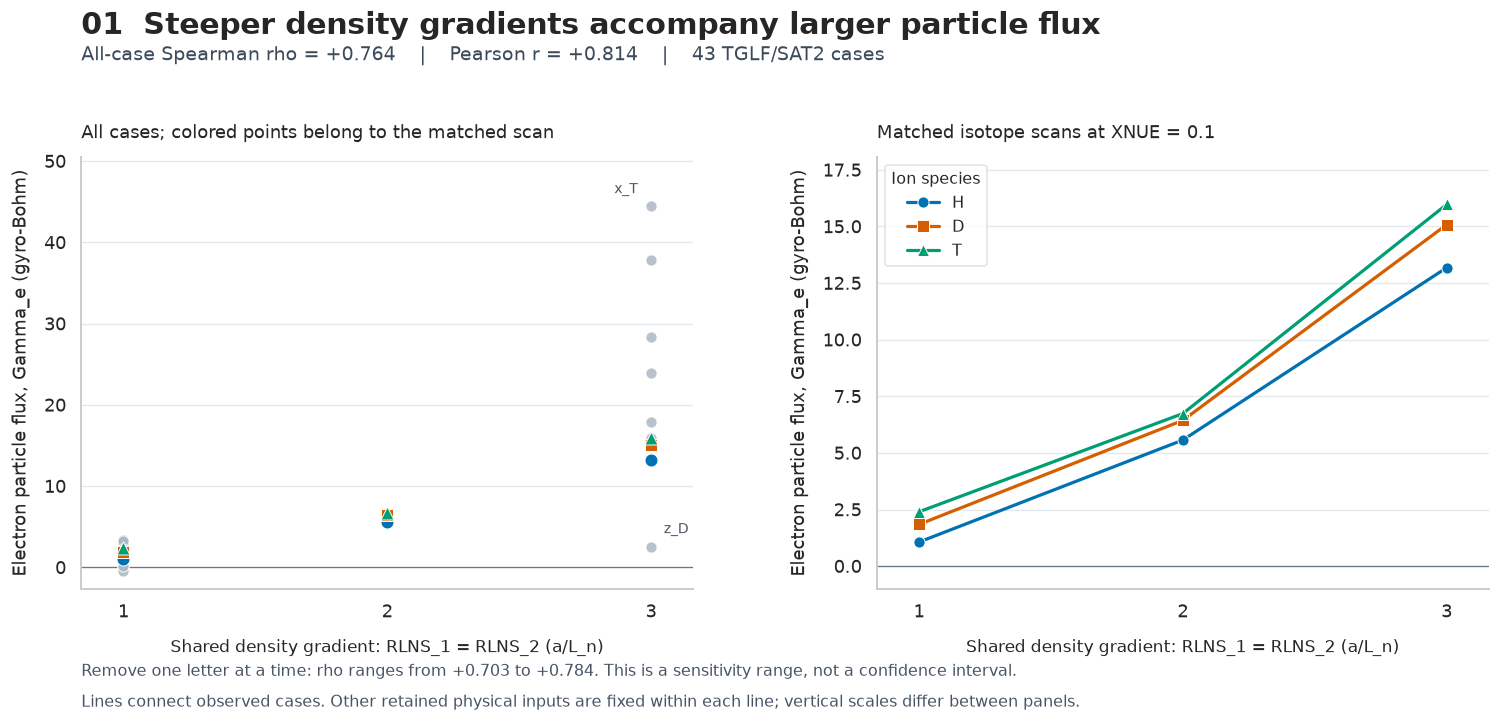

In [4]:
plot_correlation(1, 'Steeper density gradients accompany larger particle flux', '01_density_gradient_particle_flux')

## 5. Plot 2: Density gradient and electron heat flux

**Variables.** `RLNS_1 = RLNS_2` is the shared normalized density-gradient
input. `Q_e` is electron heat flux in gyro-Bohm units.

**What the plot shows.** Spearman rho is **+0.645** and Pearson r is **+0.753**.
In the matched D scan, increasing the density gradient **1 → 2 → 3** raises
`Q_e` **15.258 → 24.310 → 43.739** (`a_D`, `e_D`, `f_D`). All three isotope
lines rise, with larger increments between the last two sampled settings.

**Possible explanation.** Changing the density gradient can change the
turbulence that carries electron energy as well as particles. A change in
trapped-electron-driven transport is one candidate, since steep density
gradients can drive such turbulence
([physical context](https://arxiv.org/abs/1112.0636)). This is a hypothesis for
the observed electron-heat response, not a conclusion about the dominant mode.

**Limit.** The positive pooled association is not universal across collision
settings. In the high-collision D comparison (`XNUE = 1`), raising density
gradient 1 → 3 instead lowers `Q_e` from **8.954 to 7.628** (`k_D` → `z_D`).
The right panel holds collisions at 0.1, so it must be described with that
condition. The low-collision `x` cases help explain the large vertical spread
on the left.

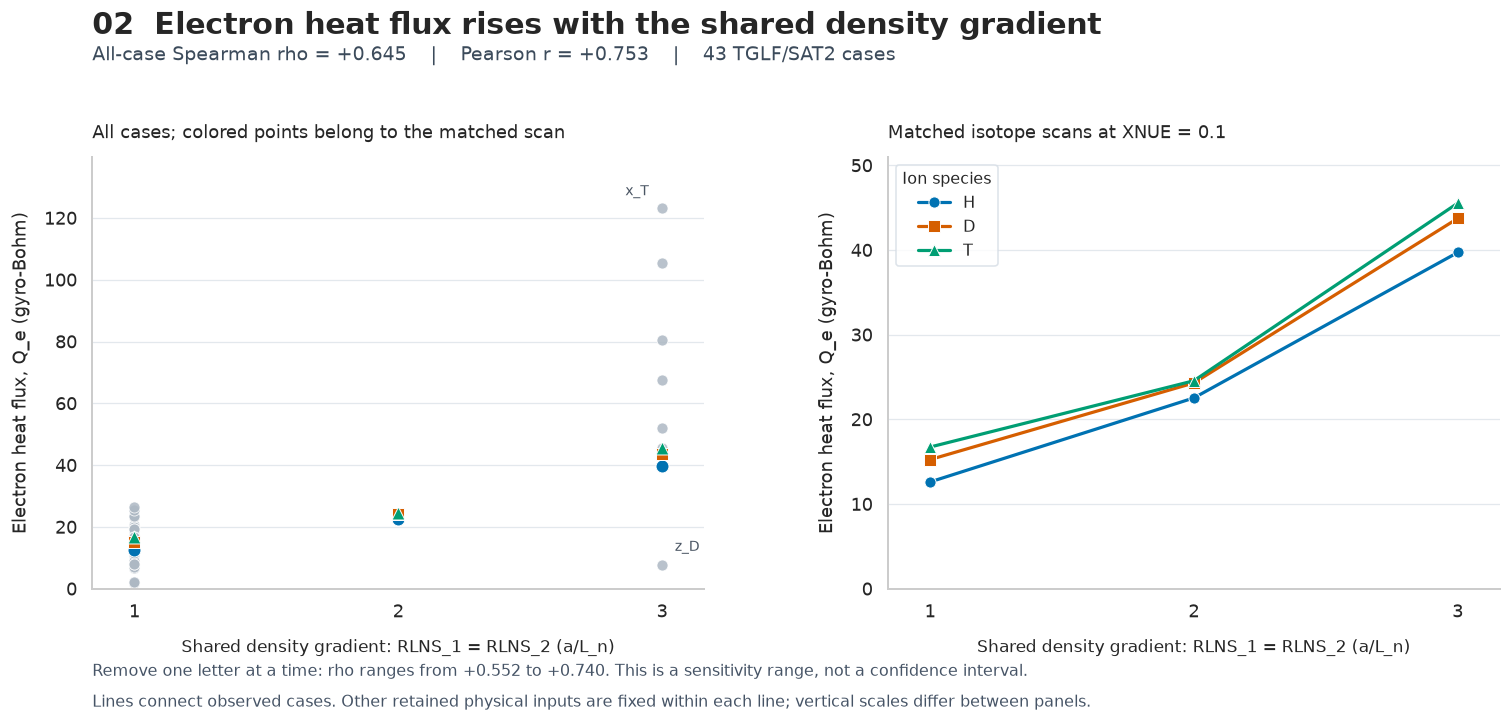

In [5]:
plot_correlation(2, 'Electron heat flux rises with the shared density gradient', '02_density_gradient_electron_heat')

## 6. Plot 3: Collision frequency and ion heat flux

**Variables.** `XNUE` is the normalized electron–ion collision frequency;
`Q_i` is ion heat flux in gyro-Bohm units. The collision axis is logarithmic.

**What the plot shows.** Spearman rho is **−0.591**, compared with Pearson
r **−0.355** on the original collision values. The stronger rank correlation
suggests a decreasing trend that a straight line on the raw collision scale
describes less well. At density gradient 1, the matched D cases give `Q_i`
**61.859 → 43.101 → 24.138** for `XNUE` **0.01 → 0.1 → 1**
(`j_D`, `a_D`, `k_D`). At density gradient 3, the values are
**104.430 → 40.768 → 6.490** (`x_D`, `f_D`, `z_D`).

**Possible explanation.** Collisions change the modeled electron response.
One possible interpretation is that they reduce a contribution to the
turbulent heat transport in these settings. TGLF has explicit electron–ion
collision terms and a SAT2 collision-model preset
([GACODE collision inputs](https://gafusion.github.io/doc/tglf/tglf_list.html#xnue)).
The total flux alone cannot identify which modes or saturation effects change.

**Limit.** The two curves cross: the density-gradient effect depends on
collision frequency. Three sampled collision settings per line do not establish
a universal logarithmic law or a transition location. This scan does not
separate ion and electron density-gradient effects.

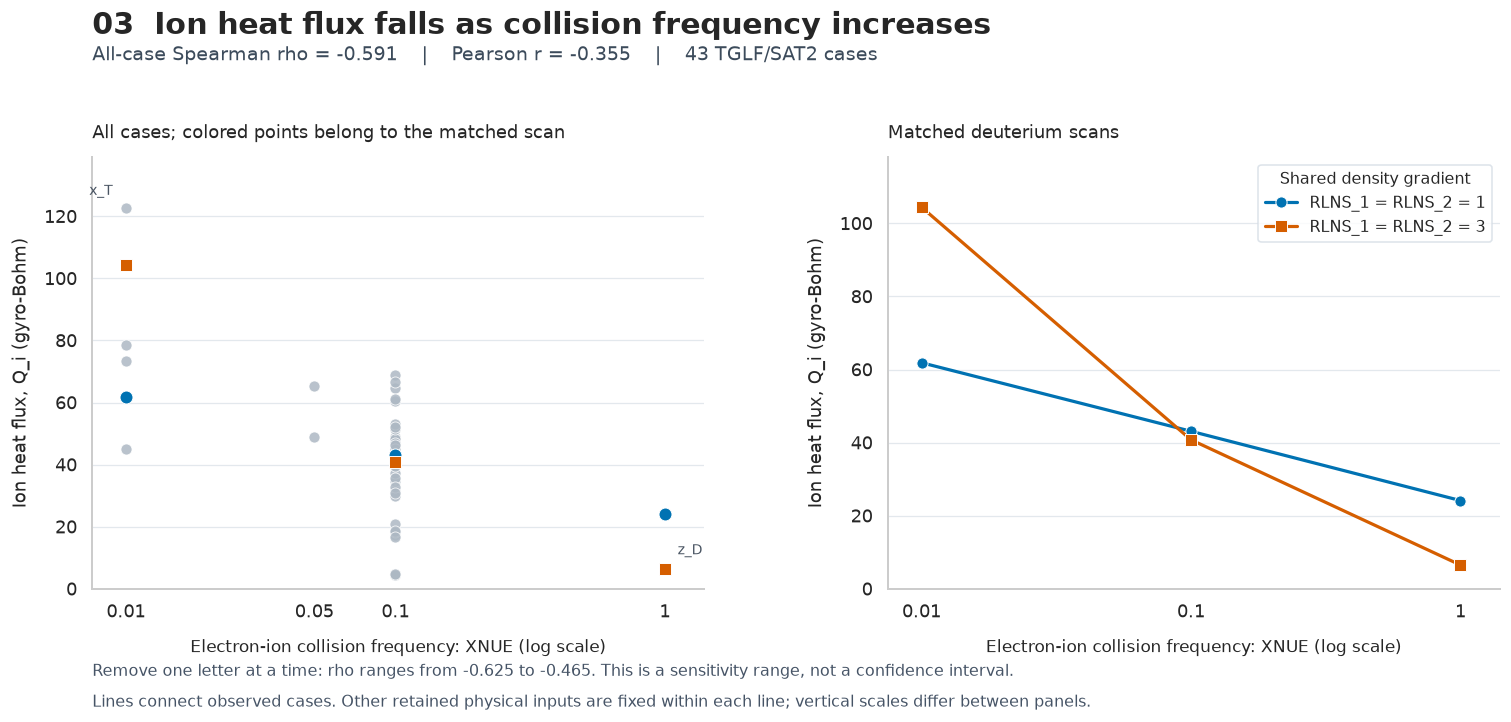

In [6]:
plot_correlation(3, 'Ion heat flux falls as collision frequency increases', '03_collision_frequency_ion_heat')

## 7. Plot 4: Temperature gradient and ion heat flux

**Variables.** `RLTS_2` is the normalized ion temperature gradient, and
`RLTS_1 = RLTS_2` throughout this dataset. `Q_i` is ion heat flux in gyro-Bohm units.

**What the plot shows.** Spearman rho is **+0.577** and Pearson r is **+0.548**.
For matched D cases, the shared gradients **1.5 → 2.25 → 3 → 3.5** give
`Q_i` **4.800 → 20.862 → 43.101 → 60.586** (`b_D`, `c_D`, `a_D`, `d_D`).
The adjacent slopes rise from about **21.4 to 29.7 to 35.0** per unit gradient,
so the response steepens over these settings. H and T also increase.

**Possible explanation.** A steeper temperature profile supplies a larger
drive for temperature-gradient turbulence. Increased ion-temperature-gradient
(ITG) drive is a plausible contributor to the ion-heat response; ITG modes are
among the modes represented by [TGLF](https://gafusion.github.io/doc/tglf.html).

**Limit.** The electron temperature gradient rises simultaneously, so this is
evidence for the joint gradient change. It does not isolate an ion-only
effect or locate a critical gradient. The large gray-point spread at gradient
3 shows that density, collisions, and other settings also affect `Q_i`.

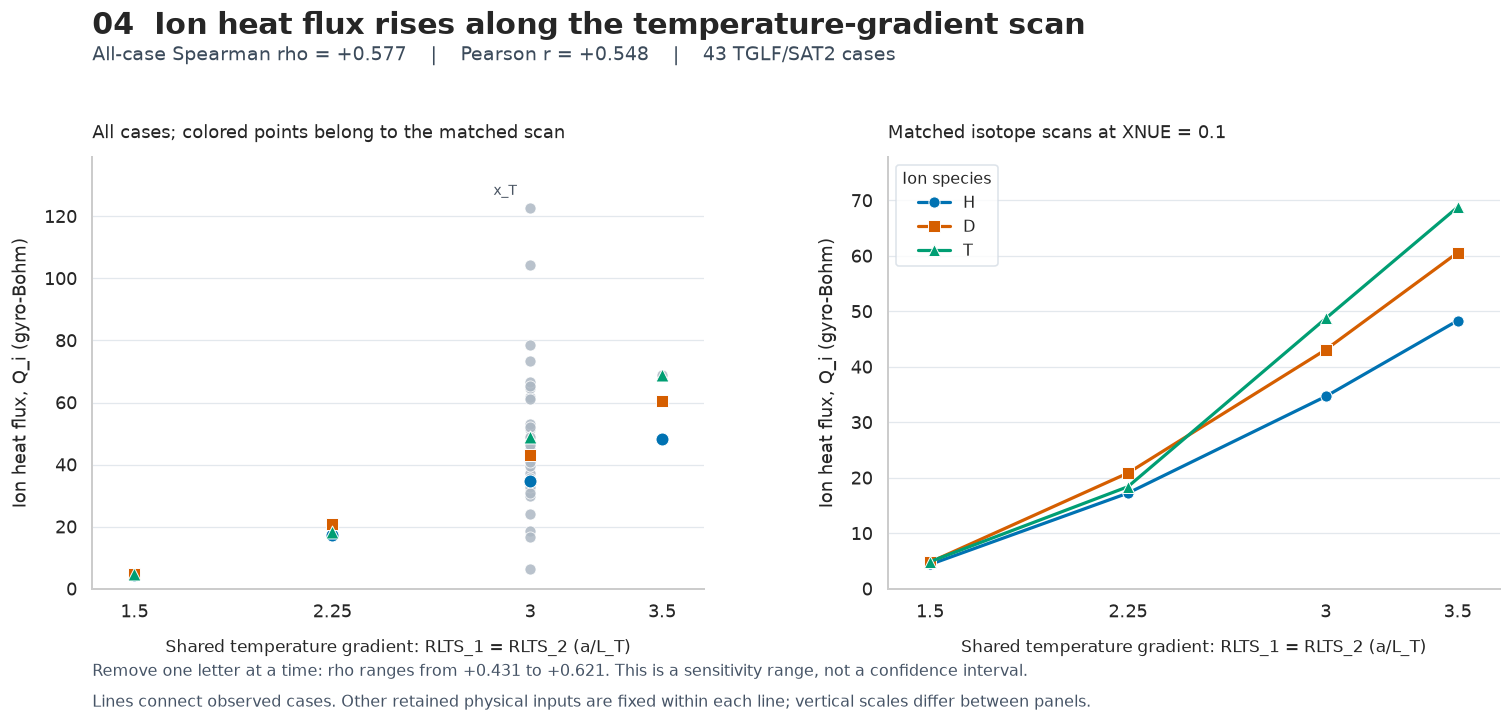

In [7]:
plot_correlation(4, 'Ion heat flux rises along the temperature-gradient scan', '04_temperature_gradient_ion_heat')

## 8. Plot 5: Temperature gradient and electron heat flux

**Variables.** `RLTS_2 = RLTS_1` represents the shared normalized temperature
gradient. `Q_e` is electron heat flux in gyro-Bohm units. The ranking retains
`RLTS_2` once to avoid counting two identical input columns as separate findings.

**What the plot shows.** Spearman rho is **+0.518**, while Pearson r is only
**+0.278**. The matched D scan is clearer than the pooled cloud: shared gradients
**1.5 → 2.25 → 3 → 3.5** give `Q_e`
**2.216 → 7.784 → 15.258 → 20.765** (`b_D`, `c_D`, `a_D`, `d_D`).
H and T also rise along their matched scans.

**Possible explanation.** Increasing the joint temperature-gradient drive
can increase the turbulence carrying electron energy. Several mode families
in [TGLF](https://gafusion.github.io/doc/tglf.html) can contribute to transport;
an increase in `Q_e` alone does not show that electron-temperature-gradient
(ETG) modes dominate.

**Limit.** Density and collision changes produce electron heat fluxes much
larger than this temperature scan at the same gradient 3. The pooled relation
therefore mixes several effects. This pair ranks only slightly above
`XNUE`–`Q_e` (absolute rho **0.513**), so fifth place is a descriptive choice,
not evidence of greater physical importance.

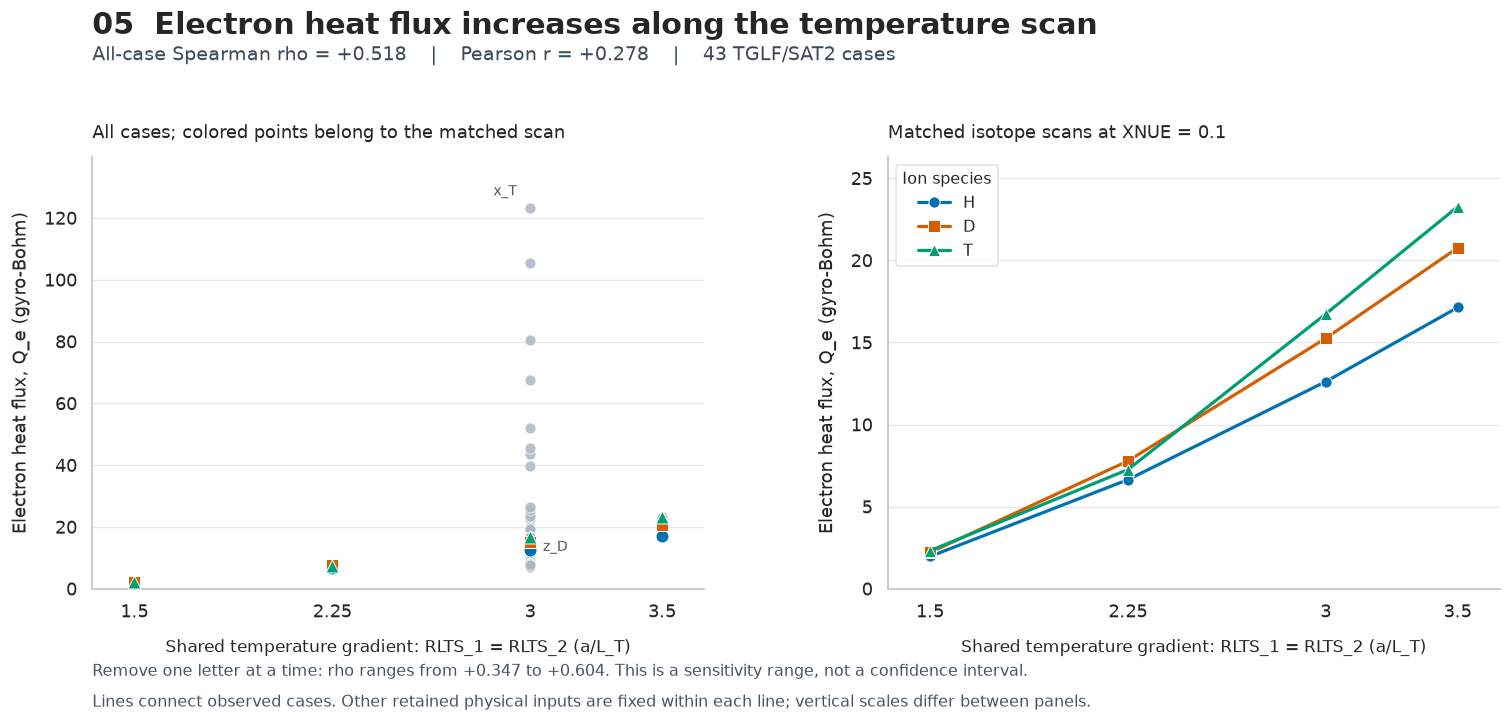

In [8]:
plot_correlation(5, 'Electron heat flux increases along the temperature scan', '05_temperature_gradient_electron_heat')

## 9. What these five plots support

The density-gradient/particle-flux pair has the largest rank correlation in
the selected scope. The collision/ion-heat plot gives a useful second story:
the density effect changes with collision frequency. The temperature scans
show increasing heat flux at fixed background settings, while the full clouds
show why one pooled relationship is insufficient for prediction.

All five rank correlations retain their sign when any one letter group is
removed, but that check does not remove confounding or validate a physical
mechanism. The separate nonlinear notebook contains the additional interaction
and prediction results. Establishing mode explanations requires mode-resolved
outputs or further simulations.

## 10. Save presentation assets and the full ranking

The ZIP contains five PNGs, five editable vector SVGs, and the written
descriptions. `top_correlations_results.json` records all 120 screened pairs,
the full 30-pair selection ranking, and the exact matched cases used in each
figure. Regenerating the plots reads the original source files and does not
depend on a previous notebook's variables or saved outputs.

In [9]:
captions = "PLOT 1: Density gradient and electron particle flux\n\n**Variables.** `RLNS_2` is the normalized ion density gradient and equals the\nelectron density gradient `RLNS_1` in every case. `Gamma_e` is electron\nparticle flux; `Gamma_i` has identical values here.\n\n**What the plot shows.** Spearman rho is **+0.764** and Pearson r is **+0.814**.\nAcross all cases, larger shared density gradients tend to have larger particle\nflux. The matched scans at `XNUE = 0.1` show this increase for H, D, and T.\nFor D, `RLNS_1 = RLNS_2` increasing **1 → 2 → 3** gives `Gamma_e`\n**1.844 → 6.438 → 15.080** gyro-Bohm units (`a_D`, `e_D`, `f_D`).\n\n**Possible explanation.** A steeper density profile can increase the outward\ndiffusive contribution and change the turbulence driving particle transport.\nDensity-gradient-driven trapped-electron turbulence is a possible mechanism;\nit has been studied in [Skyman, Nordman, and Strand](https://arxiv.org/abs/1112.0636).\nThat paper supplies physical context, not a mode identification for these runs.\n\n**Limit.** Collisions also vary among the gray points: `x_T` has much larger\nparticle flux than the baseline-collision scan, while `z_D` stays low despite\ndensity gradient 3. Both species' gradients move together, and the coefficient\ndoes not separate their individual effects.\n\nPLOT 2: Density gradient and electron heat flux\n\n**Variables.** `RLNS_1 = RLNS_2` is the shared normalized density-gradient\ninput. `Q_e` is electron heat flux in gyro-Bohm units.\n\n**What the plot shows.** Spearman rho is **+0.645** and Pearson r is **+0.753**.\nIn the matched D scan, increasing the density gradient **1 → 2 → 3** raises\n`Q_e` **15.258 → 24.310 → 43.739** (`a_D`, `e_D`, `f_D`). All three isotope\nlines rise, with larger increments between the last two sampled settings.\n\n**Possible explanation.** Changing the density gradient can change the\nturbulence that carries electron energy as well as particles. A change in\ntrapped-electron-driven transport is one candidate, since steep density\ngradients can drive such turbulence\n([physical context](https://arxiv.org/abs/1112.0636)). This is a hypothesis for\nthe observed electron-heat response, not a conclusion about the dominant mode.\n\n**Limit.** The positive pooled association is not universal across collision\nsettings. In the high-collision D comparison (`XNUE = 1`), raising density\ngradient 1 → 3 instead lowers `Q_e` from **8.954 to 7.628** (`k_D` → `z_D`).\nThe right panel holds collisions at 0.1, so it must be described with that\ncondition. The low-collision `x` cases help explain the large vertical spread\non the left.\n\nPLOT 3: Collision frequency and ion heat flux\n\n**Variables.** `XNUE` is the normalized electron–ion collision frequency;\n`Q_i` is ion heat flux in gyro-Bohm units. The collision axis is logarithmic.\n\n**What the plot shows.** Spearman rho is **−0.591**, compared with Pearson\nr **−0.355** on the original collision values. The stronger rank correlation\nsuggests a decreasing trend that a straight line on the raw collision scale\ndescribes less well. At density gradient 1, the matched D cases give `Q_i`\n**61.859 → 43.101 → 24.138** for `XNUE` **0.01 → 0.1 → 1**\n(`j_D`, `a_D`, `k_D`). At density gradient 3, the values are\n**104.430 → 40.768 → 6.490** (`x_D`, `f_D`, `z_D`).\n\n**Possible explanation.** Collisions change the modeled electron response.\nOne possible interpretation is that they reduce a contribution to the\nturbulent heat transport in these settings. TGLF has explicit electron–ion\ncollision terms and a SAT2 collision-model preset\n([GACODE collision inputs](https://gafusion.github.io/doc/tglf/tglf_list.html#xnue)).\nThe total flux alone cannot identify which modes or saturation effects change.\n\n**Limit.** The two curves cross: the density-gradient effect depends on\ncollision frequency. Three sampled collision settings per line do not establish\na universal logarithmic law or a transition location. This scan does not\nseparate ion and electron density-gradient effects.\n\nPLOT 4: Temperature gradient and ion heat flux\n\n**Variables.** `RLTS_2` is the normalized ion temperature gradient, and\n`RLTS_1 = RLTS_2` throughout this dataset. `Q_i` is ion heat flux in gyro-Bohm units.\n\n**What the plot shows.** Spearman rho is **+0.577** and Pearson r is **+0.548**.\nFor matched D cases, the shared gradients **1.5 → 2.25 → 3 → 3.5** give\n`Q_i` **4.800 → 20.862 → 43.101 → 60.586** (`b_D`, `c_D`, `a_D`, `d_D`).\nThe adjacent slopes rise from about **21.4 to 29.7 to 35.0** per unit gradient,\nso the response steepens over these settings. H and T also increase.\n\n**Possible explanation.** A steeper temperature profile supplies a larger\ndrive for temperature-gradient turbulence. Increased ion-temperature-gradient\n(ITG) drive is a plausible contributor to the ion-heat response; ITG modes are\namong the modes represented by [TGLF](https://gafusion.github.io/doc/tglf.html).\n\n**Limit.** The electron temperature gradient rises simultaneously, so this is\nevidence for the joint gradient change. It does not isolate an ion-only\neffect or locate a critical gradient. The large gray-point spread at gradient\n3 shows that density, collisions, and other settings also affect `Q_i`.\n\nPLOT 5: Temperature gradient and electron heat flux\n\n**Variables.** `RLTS_2 = RLTS_1` represents the shared normalized temperature\ngradient. `Q_e` is electron heat flux in gyro-Bohm units. The ranking retains\n`RLTS_2` once to avoid counting two identical input columns as separate findings.\n\n**What the plot shows.** Spearman rho is **+0.518**, while Pearson r is only\n**+0.278**. The matched D scan is clearer than the pooled cloud: shared gradients\n**1.5 → 2.25 → 3 → 3.5** give `Q_e`\n**2.216 → 7.784 → 15.258 → 20.765** (`b_D`, `c_D`, `a_D`, `d_D`).\nH and T also rise along their matched scans.\n\n**Possible explanation.** Increasing the joint temperature-gradient drive\ncan increase the turbulence carrying electron energy. Several mode families\nin [TGLF](https://gafusion.github.io/doc/tglf.html) can contribute to transport;\nan increase in `Q_e` alone does not show that electron-temperature-gradient\n(ETG) modes dominate.\n\n**Limit.** Density and collision changes produce electron heat fluxes much\nlarger than this temperature scan at the same gradient 3. The pooled relation\ntherefore mixes several effects. This pair ranks only slightly above\n`XNUE`–`Q_e` (absolute rho **0.513**), so fifth place is a descriptive choice,\nnot evidence of greater physical importance."
caption_intro = (
    "FIVE STRONGEST INPUT-FLUX ASSOCIATIONS\n\n"
    "Scope: 30 pairs among 10 distinct physical inputs and Q_i, Q_e, Gamma_e.\n"
    "Rank: absolute Spearman correlation across all 43 TGLF/SAT2 cases.\n"
    "These are exploratory association rankings, not significance tests.\n"
    "Left panels show all cases; right panels show matched scans. Lines connect observed cases.\n"
    "The panels have separate vertical scales. Both species' gradients vary together.\n"
    "Possible explanations are hypotheses; total fluxes do not identify instability modes.\n\n"
)
caption_path = OUTPUT_DIR / "plot_descriptions.txt"
caption_path.write_text(caption_intro + captions + "\n", encoding="utf-8")
payload = {
    "case_count": len(plot_df), "letter_count": int(plot_df["letter"].nunique()),
    "selection": "Descending absolute Spearman correlation among 30 input-primary-flux pairs",
    "all_pairs": json.loads(all_pairs.to_json(orient="records", double_precision=15)),
    "input_flux_ranking": json.loads(ranking.to_json(orient="records", double_precision=15)),
    "plots": plot_records,
}
result_path = analysis_dir / "top_correlations_results.json"
result_path.write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n")
asset_paths = [analysis_dir / name for record in plot_records for name in record["files"]]
assert len(plot_records) == 5 and len(asset_paths) == 10
assert all(p.is_file() and p.stat().st_size > 10000 for p in asset_paths)
archive_path = analysis_dir / "top_correlations_presentation_assets.zip"
with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for asset in asset_paths + [caption_path]:
        archive.write(asset, arcname=asset.name)
print(f"Saved five PNG/SVG figures and descriptions in {OUTPUT_DIR}")
print(f"Presentation assets: {archive_path}")
print(f"Full ranking and matched-case audit: {result_path}")

Saved five PNG/SVG figures and descriptions in /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/task1/analysis/figures/top_correlations
Presentation assets: /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/task1/analysis/top_correlations_presentation_assets.zip
Full ranking and matched-case audit: /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/task1/analysis/top_correlations_results.json
